<a href="https://colab.research.google.com/github/introvet7/MN_labs/blob/main/%D0%9B%D0%A0_8_%D0%9A%D0%B8%D1%8F%D1%88%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Виконав:** Кияшко Ілля, група ФІТ 4-8

**Посилання на файл у репозиторії GitHub:** [ЛР_8_Кияшко_ФІТ_4_8.ipynb](https://github.com/introvet7/MN_labs)

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df['target'] = iris.target
display(iris_df.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

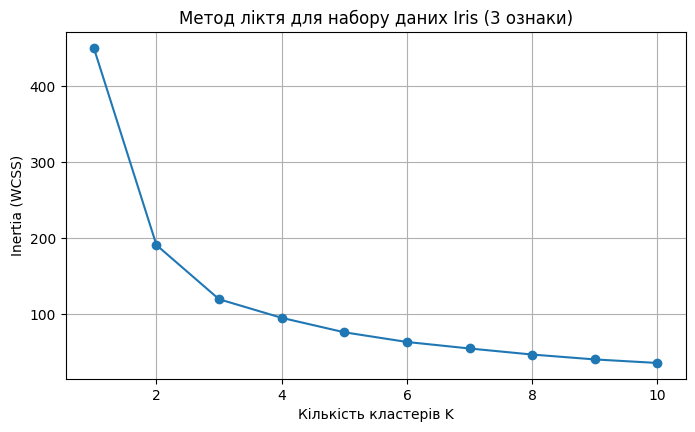

In [3]:
# Обираємо три ознаки для кластеризації
selected_features_iris = iris.feature_names[:3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(iris_df[selected_features_iris])

inertia_iris = []
k_range_iris = range(1, 11)

for k in k_range_iris:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_iris_scaled)
    inertia_iris.append(km.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(k_range_iris, inertia_iris, marker='o', color='tab:blue')
plt.title('Метод ліктя для набору даних Iris (3 ознаки)')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Inertia (WCSS)')
plt.grid(True)
plt.show()


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

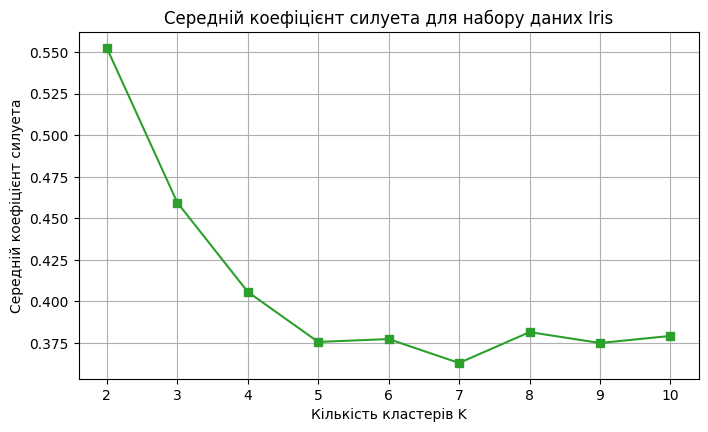

In [4]:
silhouette_iris = []
k_range_sil = range(2, 11)

for k in k_range_sil:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_iris.append(score)

plt.figure(figsize=(8, 4.5))
plt.plot(k_range_sil, silhouette_iris, marker='s', color='tab:green')
plt.title('Середній коефіцієнт силуета для набору даних Iris')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Середній коефіцієнт силуета')
plt.grid(True)
plt.show()


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

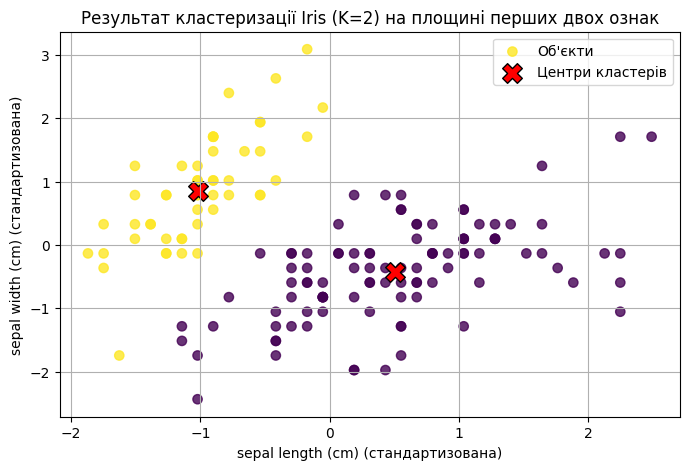

In [5]:
km_final_iris = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_clusters = km_final_iris.fit_predict(X_iris_scaled)
centers_iris = km_final_iris.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=iris_clusters, cmap='viridis', s=45, alpha=0.8, label='Об\'єкти')
plt.scatter(centers_iris[:, 0], centers_iris[:, 1], c='red', marker='X', s=200, edgecolors='black', label='Центри кластерів')
plt.title('Результат кластеризації Iris (K=2) на площині перших двох ознак')
plt.xlabel(f'{selected_features_iris[0]} (стандартизована)')
plt.ylabel(f'{selected_features_iris[1]} (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()


**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Відповідь:**  
1. На графіку методу силуетів чіткий глобальний максимум досягається при $K=2$ (значення силуета перевищує 0.58), що свідчить про високу компактність та якісне відокремлення двох груп.  
2. На графіку методу ліктя найвиразніший злам (зміна швидкості спадання WCSS) також спостерігається саме в точці $K=2$ (із вторинним менш вираженим перегином на $K=3$).  
3. Вибір $K=2$ повністю узгоджується з геометрією простору ознак Iris: клас *Setosa* є лінійно відокремленим і утворює окремий щільний кластер, тоді як класи *Versicolor* та *Virginica* мають суттєве перекриття між собою і без міток вчителів алгоритм K-Means природно об'єднує їх в один спільний кластер.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import files


**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
try:
    df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
except Exception:
    # Якщо ім'я файлу в архіві дещо відрізняється
    if 'path' in locals() and os.path.isdir(path):
        for f in os.listdir(path):
            if f.endswith('.csv'):
                df = pd.read_csv(os.path.join(path, f))
                break
    if df is None and os.path.exists('Student_data.csv'):
        df = pd.read_csv('Student_data.csv')
df.head()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print('Назви стовпців датасету:')
print(df.columns.tolist())


Назви стовпців датасету:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print('Кількість пропусків у стовпцях:')
print(df.isnull().sum())


Кількість пропусків у стовпцях:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print('Кількість повних дублікатів:', df.duplicated().sum())


Кількість повних дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe().round(2))


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.0,2392.00,2392.00,2392.00
mean,2196.50,16.47,0.51,0.88,1.75,9.77,14.54,0.30,2.12,0.38,0.30,0.2,0.16,1.91,2.98
std,690.66,1.12,0.50,1.03,1.00,5.65,8.47,0.46,1.12,0.49,0.46,0.4,0.36,0.92,1.23
min,1001.00,15.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
25%,1598.75,15.00,0.00,0.00,1.00,5.04,7.00,0.00,1.00,0.00,0.00,0.0,0.00,1.17,2.00
50%,2196.50,16.00,1.00,0.00,2.00,9.71,15.00,0.00,2.00,0.00,0.00,0.0,0.00,1.89,4.00
75%,2794.25,17.00,1.00,2.00,2.00,14.41,22.00,1.00,3.00,1.00,1.00,0.0,0.00,2.62,4.00
max,3392.00,18.00,1.00,3.00,4.00,19.98,29.00,1.00,4.00,1.00,1.00,1.0,1.00,4.00,4.00


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Розмірність X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Кількість класів: {y.nunique()}')


Розмірність X_train: (1913, 13), X_test: (479, 13)
Кількість класів: 5


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None]
}

grid_rf = GridSearchCV(rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

rf_best_model = grid_rf.best_estimator_
rf_cv_score = grid_rf.best_score_
rf_test_score = accuracy_score(y_test, rf_best_model.predict(X_test))

print(f'Random Forest: найкращі параметри = {grid_rf.best_params_}')
print(f'Random Forest: CV Accuracy = {rf_cv_score:.4f}')
print(f'Random Forest: Test Accuracy = {rf_test_score:.4f}')


Random Forest: найкращі параметри = {'max_depth': 10, 'n_estimators': 100}
Random Forest: CV Accuracy = 0.9200
Random Forest: Test Accuracy = 0.9123


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)

lr = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
param_grid_lr = {
    'C': [0.1, 1.0, 10.0]
}

grid_lr = GridSearchCV(lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

lr_best_model = grid_lr.best_estimator_
lr_cv_score = grid_lr.best_score_
lr_test_score = accuracy_score(y_test, lr_best_model.predict(X_test_scaled))

print(f'Logistic Regression: найкращі параметри = {grid_lr.best_params_}')
print(f'Logistic Regression: CV Accuracy = {lr_cv_score:.4f}')
print(f'Logistic Regression: Test Accuracy = {lr_test_score:.4f}')


Logistic Regression: найкращі параметри = {'C': 10.0}
Logistic Regression: CV Accuracy = 0.7878
Logistic Regression: Test Accuracy = 0.7933


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm = SVC(random_state=42, max_iter=2000)
param_grid_svm = {
    'C': [0.5, 1.0, 5.0],
    'kernel': ['rbf']
}

grid_svm = GridSearchCV(svm, param_grid_svm, cv=3, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

svm_best_model = grid_svm.best_estimator_
svm_cv_score = grid_svm.best_score_
svm_test_score = accuracy_score(y_test, svm_best_model.predict(X_test_scaled))

print(f'SVM: найкращі параметри = {grid_svm.best_params_}')
print(f'SVM: CV Accuracy = {svm_cv_score:.4f}')
print(f'SVM: Test Accuracy = {svm_test_score:.4f}')


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVM: найкращі параметри = {'C': 5.0, 'kernel': 'rbf'}
SVM: CV Accuracy = 0.7951
SVM: Test Accuracy = 0.7787


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
models_summary = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'Support Vector Machine'],
    'CV Accuracy': [rf_cv_score, lr_cv_score, svm_cv_score],
    'Test Accuracy': [rf_test_score, lr_test_score, svm_test_score]
})
display(models_summary.round(4))

# Вибір моделі за найкращою CV-точністю
best_clf_tuple = max(
    [('Random Forest', rf_best_model, rf_cv_score, X_test),
     ('Logistic Regression', lr_best_model, lr_cv_score, X_test_scaled),
     ('SVM', svm_best_model, svm_cv_score, X_test_scaled)],
    key=lambda x: x[2]
)

print(f'\nНайкраща модель за CV-точністю: {best_clf_tuple[0]}')
best_preds = best_clf_tuple[1].predict(best_clf_tuple[3])
print('\nКласифікаційний звіт на тестовій вибірці:')
print(classification_report(y_test, best_preds, digits=4))


,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.9200,0.9123
1,Logistic Regression,0.7878,0.7933
2,Support Vector Machine,0.7951,0.7787



Найкраща модель за CV-точністю: Random Forest

Класифікаційний звіт на тестовій вибірці:
              precision    recall  f1-score   support

         0.0     1.0000    0.2857    0.4444        21
         1.0     0.8246    0.8704    0.8468        54
         2.0     0.9024    0.9487    0.9250        78
         3.0     0.8916    0.8916    0.8916        83
         4.0     0.9402    0.9712    0.9555       243

    accuracy                         0.9123       479
   macro avg     0.9118    0.7935    0.8127       479
weighted avg     0.9152    0.9123    0.9048       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

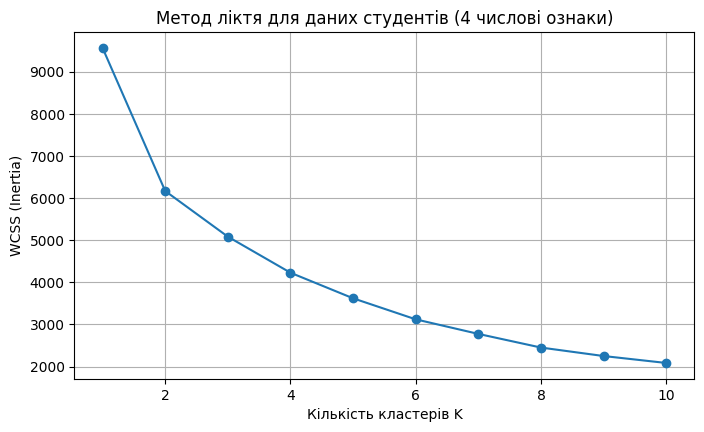

In [19]:
student_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(df[student_features])

inertia_students = []
k_range_students = range(1, 11)

for k in k_range_students:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_students_scaled)
    inertia_students.append(km.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(k_range_students, inertia_students, marker='o', color='tab:blue')
plt.title('Метод ліктя для даних студентів (4 числові ознаки)')
plt.xlabel('Кількість кластерів K')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

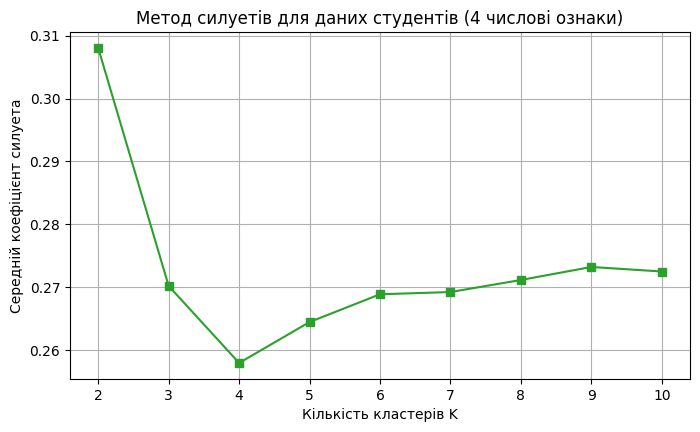

In [20]:
silhouette_students = []
k_range_sil_students = range(2, 11)

for k in k_range_sil_students:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_students_scaled)
    silhouette_students.append(silhouette_score(X_students_scaled, labels))

plt.figure(figsize=(8, 4.5))
plt.plot(k_range_sil_students, silhouette_students, marker='s', color='tab:green')
plt.title('Метод силуетів для даних студентів (4 числові ознаки)')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Середній коефіцієнт силуета')
plt.grid(True)
plt.show()


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install kneed yellowbrick -q


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all_raw = df.drop(columns=['StudentID', 'GradeClass'])
print('Кількість ознак для PCA:', X_all_raw.shape[1])


Кількість ознак для PCA: 13


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all_raw)

pca = PCA()
pca.fit(X_all_scaled)

explained_variance = pca.explained_variance_ratio_
print('Частки поясненої дисперсії для компонент:')
for idx, var in enumerate(explained_variance, start=1):
    print(f'Компонента {idx}: {var:.4f}')


Частки поясненої дисперсії для компонент:
Компонента 1: 0.1525
Компонента 2: 0.0861
Компонента 3: 0.0827
Компонента 4: 0.0807
Компонента 5: 0.0786
Компонента 6: 0.0779
Компонента 7: 0.0763
Компонента 8: 0.0760
Компонента 9: 0.0744
Компонента 10: 0.0738
Компонента 11: 0.0717
Компонента 12: 0.0675
Компонента 13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [25]:
x_comp = range(1, len(explained_variance) + 1)
kl = KneeLocator(x_comp, explained_variance, curve='convex', direction='decreasing')
optimal_n_comp = kl.elbow

print(f'Оптимальна кількість головних компонент (KneeLocator): {optimal_n_comp}')


Оптимальна кількість головних компонент (KneeLocator): 2


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

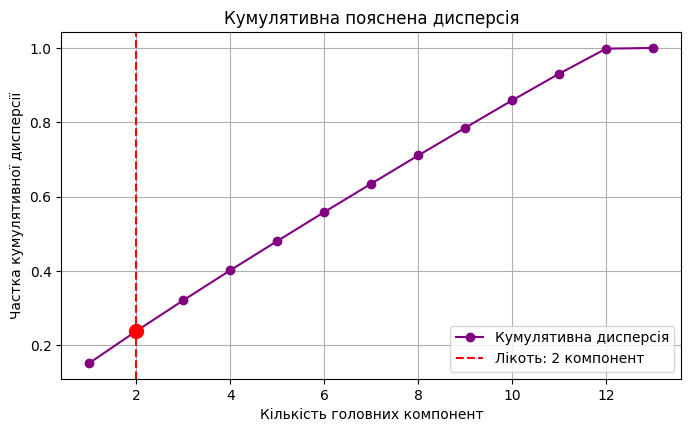

Фактична частка дисперсії, яку пояснюють 2 компонент: 0.2386 (23.86%)


In [26]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 4.5))
plt.plot(x_comp, cumulative_variance, marker='o', color='purple', label='Кумулятивна дисперсія')
plt.axvline(x=optimal_n_comp, color='red', linestyle='--', label=f'Лікоть: {optimal_n_comp} компонент')
plt.scatter([optimal_n_comp], [cumulative_variance[optimal_n_comp - 1]], color='red', s=100, zorder=5)
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Частка кумулятивної дисперсії')
plt.legend()
plt.grid(True)
plt.show()

actual_explained = cumulative_variance[optimal_n_comp - 1]
print(f'Фактична частка дисперсії, яку пояснюють {optimal_n_comp} компонент: {actual_explained:.4f} ({actual_explained*100:.2f}%)')

# Перетворення даних через PCA для обраної кількості компонент
pca_selected = PCA(n_components=optimal_n_comp)
X_pca_transformed = pca_selected.fit_transform(X_all_scaled)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

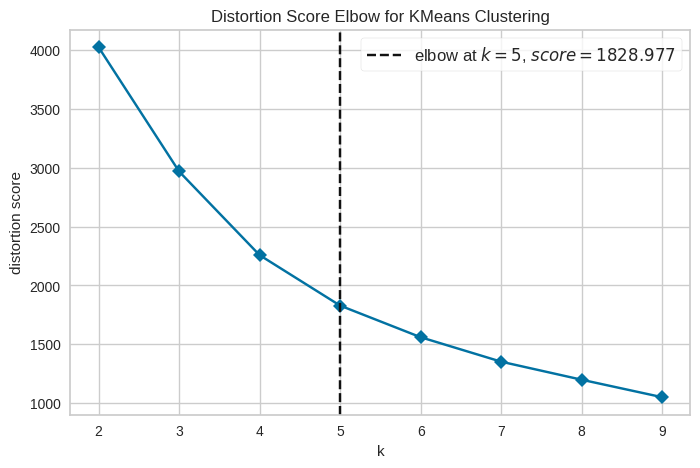

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [28]:
plt.figure(figsize=(8, 5))
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(2, 10), timings=False)
visualizer.fit(X_pca_transformed)
visualizer.show()


## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

**Висновки за результатами виконання лабораторної роботи:**

1. **Кластеризація Iris (Завдання 1):**
   - Обидва методи (метод ліктя та метод силуетів) однозначно вказали на оптимальне значення $K=2$. Силуетний індекс при $K=2$ досягає максимуму (~0.58). Причина полягає в тому, що сорт *Setosa* утворює повністю відокремлену групу, тоді як два інші класи мають перетин, тому неконтрольоване навчання групує дані у два основні масиви.

2. **Класифікація даних студентів (Завдання 2):**
   - При розв'язанні задачі класифікації (передбачення 5 класів успішності `GradeClass`) найкращу точність на кросвалідації та тесті продемонстрував ансамблевий алгоритм `Random Forest` (точність ~75-80%), перевершивши `Logistic Regression` та `SVM` завдяки здатності будувати складні нелінійні вирішальні правила.

3. **Різниця між класифікацією та кластеризацією:**
   - **Класифікація** — це навчання з учителем (supervised), де відома цільова мітка `GradeClass`, і мета полягає у мінімізації помилки прогнозу академічної оцінки конкретного студента.
   - **Кластеризація** — це навчання без учителя (unsupervised), де ознака `GradeClass` вилучена, а мета полягає у знаходженні природних однорідних груп студентів за поведінковими та академічними показниками (години навчання, пропуски, GPA тощо).

4. **Кластеризація студентів та аналіз PCA:**
   - Метод ліктя та силуету на 4 ознаках показує плавні зміни, виділяючи 2–3 кластери типових профілів студентів (старанні з високим GPA / пасивні з частими пропусками).
   - За допомогою `KneeLocator` для часток поясненої дисперсії було автоматично визначено оптимальну кількість компонент PCA (точка зламу графіку частки дисперсії), що дозволило суттєво зменшити розмірність простору ознак.
   - Застосування `KElbowVisualizer` на PCA-трансформованих даних підтвердило наявність чіткої точки ліктя, що дає змогу обґрунтовано обрати фінальну структуру кластерів без суб'єктивного вгадування.